# Exploratory Data Analysis — Employee Attrition

## Objective
Analyze employee attrition, department differences, income,
overtime, job roles, and job satisfaction using pandas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = (
    Path("data") /
    "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

# The notebook is inside the notebooks folder.
# Look in the project root's data folder.
if not DATA_PATH.exists():
    DATA_PATH = (
        Path("..") /
        "data" /
        "WA_Fn-UseC_-HR-Employee-Attrition.csv"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 1470
Columns: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1. Data Overview and Quality Checks

In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values by column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe())

Dataset shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types:
Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber       

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince


Duplicate rows: 0

Numeric summary:


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## 2. Summary Statistics

In [3]:
numeric_df = df.select_dtypes(include="number")

summary_stats = numeric_df.agg(
    ["mean", "median", "min", "max", "std"]
).T

summary_stats.columns = [
    "Mean", "Median", "Minimum", "Maximum", "Std_Dev"
]

display(summary_stats.round(2))

,Mean,Median,Minimum,Maximum,Std_Dev
Age,36.92,36.0,18.0,60.0,9.14
DailyRate,802.49,802.0,102.0,1499.0,403.51
DistanceFromHome,9.19,7.0,1.0,29.0,8.11
Education,2.91,3.0,1.0,5.0,1.02
EmployeeCount,1.00,1.0,1.0,1.0,0.00
EmployeeNumber,1024.87,1020.5,1.0,2068.0,602.02
EnvironmentSatisfaction,2.72,3.0,1.0,4.0,1.09
HourlyRate,65.89,66.0,30.0,100.0,20.33
JobInvolvement,2.73,3.0,1.0,4.0,0.71
JobLevel,2.06,2.0,1.0,5.0,1.11


In [9]:
key_columns = [
    col for col in [
        "Age",
        "MonthlyIncome",
        "YearsAtCompany",
        "JobSatisfaction",
        "WorkLifeBalance"
    ]
    if col in df.columns
]

display(summary_stats.loc[key_columns].round(2))

,Mean,Median,Minimum,Maximum,Std_Dev
Age,36.92,36.0,18.0,60.0,9.14
MonthlyIncome,6502.93,4919.0,1009.0,19999.0,4707.96
YearsAtCompany,7.01,5.0,0.0,40.0,6.13
JobSatisfaction,2.73,3.0,1.0,4.0,1.10
WorkLifeBalance,2.76,3.0,1.0,4.0,0.71


## 3. Group Comparisons

In [4]:
df["AttritionFlag"] = (
    df["Attrition"].astype(str).str.strip().str.lower().eq("yes")
).astype(int)

print("Employees who left:", int(df["AttritionFlag"].sum()))
print("Employees who stayed:", int((df["AttritionFlag"] == 0).sum()))

Employees who left: 237
Employees who stayed: 1233


compare departments:

In [5]:
department_analysis = (
    df.groupby("Department")
    .agg(
        Employee_Count=("Attrition", "size"),
        Employees_Left=("AttritionFlag", "sum"),
        Average_Age=("Age", "mean"),
        Average_Monthly_Income=("MonthlyIncome", "mean"),
        Average_Years_At_Company=("YearsAtCompany", "mean")
    )
)

department_analysis["Attrition_Rate_Pct"] = (
    department_analysis["Employees_Left"]
    / department_analysis["Employee_Count"] * 100
)

display(department_analysis.round(2))

,Employee_Count,Employees_Left,Average_Age,Average_Monthly_Income,Average_Years_At_Company,Attrition_Rate_Pct
Department,,,,,,
Human Resources,63,12,37.81,6654.51,7.24,19.05
Research & Development,961,133,37.04,6281.25,6.86,13.84
Sales,446,92,36.54,6959.17,7.28,20.63


Compare gender groups:

In [6]:
gender_analysis = (
    df.groupby("Gender")
    .agg(
        Employee_Count=("Attrition", "size"),
        Employees_Left=("AttritionFlag", "sum"),
        Average_Monthly_Income=("MonthlyIncome", "mean")
    )
)

gender_analysis["Attrition_Rate_Pct"] = (
    gender_analysis["Employees_Left"]
    / gender_analysis["Employee_Count"] * 100
)

display(gender_analysis.round(2))

,Employee_Count,Employees_Left,Average_Monthly_Income,Attrition_Rate_Pct
Gender,,,,
Female,588,87,6686.57,14.80
Male,882,150,6380.51,17.01


Compare overtime groups:

In [7]:
overtime_analysis = (
    df.groupby("OverTime")
    .agg(
        Employee_Count=("Attrition", "size"),
        Employees_Left=("AttritionFlag", "sum"),
        Average_Monthly_Income=("MonthlyIncome", "mean")
    )
)

overtime_analysis["Attrition_Rate_Pct"] = (
    overtime_analysis["Employees_Left"]
    / overtime_analysis["Employee_Count"] * 100
)

display(overtime_analysis.round(2))

,Employee_Count,Employees_Left,Average_Monthly_Income,Attrition_Rate_Pct
OverTime,,,,
No,1054,110,6484.93,10.44
Yes,416,127,6548.55,30.53


## 4. Correlation Analysis


In [8]:
excluded_columns = [
    "EmployeeNumber",
    "EmployeeCount",
    "StandardHours"
]

corr_df = df.select_dtypes(include="number").drop(
    columns=excluded_columns,
    errors="ignore"
)

# Remove columns that have no variation.
corr_df = corr_df.loc[:, corr_df.nunique() > 1]

correlation_matrix = corr_df.corr()

display(correlation_matrix.round(3))

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AttritionFlag
Age,1.000,0.011,-0.002,0.208,0.010,0.024,0.030,0.510,-0.005,0.498,0.028,0.300,0.004,0.002,0.054,0.038,0.680,-0.020,-0.021,0.311,0.213,0.217,0.202,-0.159
DailyRate,0.011,1.000,-0.005,-0.017,0.018,0.023,0.046,0.003,0.031,0.008,-0.032,0.038,0.023,0.000,0.008,0.042,0.015,0.002,-0.038,-0.034,0.010,-0.033,-0.026,-0.057
DistanceFromHome,-0.002,-0.005,1.000,0.021,-0.016,0.031,0.009,0.005,-0.004,-0.017,0.027,-0.029,0.040,0.027,0.007,0.045,0.005,-0.037,-0.027,0.010,0.019,0.010,0.014,0.078
Education,0.208,-0.017,0.021,1.000,-0.027,0.017,0.042,0.102,-0.011,0.095,-0.026,0.126,-0.011,-0.025,-0.009,0.018,0.148,-0.025,0.010,0.069,0.060,0.054,0.069,-0.031
EnvironmentSatisfaction,0.010,0.018,-0.016,-0.027,1.000,-0.050,-0.008,0.001,-0.007,-0.006,0.038,0.013,-0.032,-0.030,0.008,0.003,-0.003,-0.019,0.028,0.001,0.018,0.016,-0.005,-0.103
HourlyRate,0.024,0.023,0.031,0.017,-0.050,1.000,0.043,-0.028,-0.071,-0.016,-0.015,0.022,-0.009,-0.002,0.001,0.050,-0.002,-0.009,-0.005,-0.020,-0.024,-0.027,-0.020,-0.007
JobInvolvement,0.030,0.046,0.009,0.042,-0.008,0.043,1.000,-0.013,-0.021,-0.015,-0.016,0.015,-0.017,-0.029,0.034,0.022,-0.006,-0.015,-0.015,-0.021,0.009,-0.024,0.026,-0.130
JobLevel,0.510,0.003,0.005,0.102,0.001,-0.028,-0.013,1.000,-0.002,0.950,0.040,0.143,-0.035,-0.021,0.022,0.014,0.782,-0.018,0.038,0.535,0.389,0.354,0.375,-0.169
JobSatisfaction,-0.005,0.031,-0.004,-0.011,-0.007,-0.071,-0.021,-0.002,1.000,-0.007,0.001,-0.056,0.020,0.002,-0.012,0.011,-0.020,-0.006,-0.019,-0.004,-0.002,-0.018,-0.028,-0.103
MonthlyIncome,0.498,0.008,-0.017,0.095,-0.006,-0.016,-0.015,0.950,-0.007,1.000,0.035,0.150,-0.027,-0.017,0.026,0.005,0.773,-0.022,0.031,0.514,0.364,0.345,0.344,-0.160


The top three unique pairs by absolute correlation strength

In [10]:
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

top_3_correlations = (
    upper_triangle.stack()
    .rename("Correlation")
    .to_frame()
)

top_3_correlations["Absolute_Correlation"] = (
    top_3_correlations["Correlation"].abs()
)

top_3_correlations = top_3_correlations.sort_values(
    "Absolute_Correlation",
    ascending=False
).head(3)

display(top_3_correlations.round(3))

Correlation  Absolute_Correlation
JobLevel          MonthlyIncome            0.950                 0.950
                  TotalWorkingYears        0.782                 0.782
PercentSalaryHike PerformanceRating        0.774                 0.774

## 5. Business Questions and Numeric Answers

Each answer is calculated directly from the employee dataset.
Attrition rate means the percentage of employees in a group
whose Attrition value is Yes.

In [11]:
# Business Question 1:
# Which department has the highest attrition rate?

department_rates = (
    df.groupby("Department")
    .agg(
        Total_Employees=("AttritionFlag", "size"),
        Employees_Left=("AttritionFlag", "sum")
    )
)

department_rates["Attrition_Rate_Pct"] = (
    department_rates["Employees_Left"]
    / department_rates["Total_Employees"] * 100
)

highest_department = department_rates[
    "Attrition_Rate_Pct"
].idxmax()

print("QUESTION 1: Which department has the highest attrition rate?")
print("Department:", highest_department)
print(
    "Attrition rate:",
    round(department_rates.loc[
        highest_department, "Attrition_Rate_Pct"
    ], 2), "%"
)
print(
    "Employees who left:",
    int(department_rates.loc[highest_department, "Employees_Left"])
)
print(
    "Total employees:",
    int(department_rates.loc[highest_department, "Total_Employees"])
)


# Business Question 2:
# Is overtime associated with employee attrition?

overtime_rates = (
    df.groupby("OverTime")
    .agg(
        Total_Employees=("AttritionFlag", "size"),
        Employees_Left=("AttritionFlag", "sum")
    )
)

overtime_rates["Attrition_Rate_Pct"] = (
    overtime_rates["Employees_Left"]
    / overtime_rates["Total_Employees"] * 100
)

print("\nQUESTION 2: Is overtime associated with attrition?")
display(overtime_rates.round(2))

if {"Yes", "No"}.issubset(overtime_rates.index):
    difference = (
        overtime_rates.loc["Yes", "Attrition_Rate_Pct"]
        - overtime_rates.loc["No", "Attrition_Rate_Pct"]
    )

    print(
        "Attrition-rate difference (overtime minus no overtime):",
        round(difference, 2), "percentage points"
    )


# Business Question 3:
# How does monthly income differ between employees
# who leave and employees who stay?

income_by_attrition = (
    df.groupby("Attrition")["MonthlyIncome"]
    .agg(["count", "mean", "median", "min", "max"])
)

print("\nQUESTION 3: How does monthly income differ by attrition?")
display(income_by_attrition.round(2))

if {"Yes", "No"}.issubset(income_by_attrition.index):
    income_difference = (
        income_by_attrition.loc["No", "mean"]
        - income_by_attrition.loc["Yes", "mean"]
    )

    print(
        "Mean income difference (stayed minus left):",
        round(income_difference, 2)
    )


# Business Question 4:
# Which job role has the highest attrition rate?

role_rates = (
    df.groupby("JobRole")
    .agg(
        Total_Employees=("AttritionFlag", "size"),
        Employees_Left=("AttritionFlag", "sum")
    )
)

role_rates["Attrition_Rate_Pct"] = (
    role_rates["Employees_Left"]
    / role_rates["Total_Employees"] * 100
)

highest_role = role_rates["Attrition_Rate_Pct"].idxmax()

print("\nQUESTION 4: Which job role has the highest attrition rate?")
print("Job role:", highest_role)
print(
    "Attrition rate:",
    round(role_rates.loc[highest_role, "Attrition_Rate_Pct"], 2),
    "%"
)
print(
    "Employees who left:",
    int(role_rates.loc[highest_role, "Employees_Left"])
)
print(
    "Total employees:",
    int(role_rates.loc[highest_role, "Total_Employees"])
)


# Business Question 5:
# How does job satisfaction relate to attrition?

satisfaction_rates = (
    df.groupby("JobSatisfaction")
    .agg(
        Total_Employees=("AttritionFlag", "size"),
        Employees_Left=("AttritionFlag", "sum")
    )
)

satisfaction_rates["Attrition_Rate_Pct"] = (
    satisfaction_rates["Employees_Left"]
    / satisfaction_rates["Total_Employees"] * 100
)

print("\nQUESTION 5: How does job satisfaction relate to attrition?")
display(satisfaction_rates.round(2))

lowest_satisfaction = satisfaction_rates[
    "Attrition_Rate_Pct"
].idxmax()

print(
    "Satisfaction score with the highest attrition rate:",
    lowest_satisfaction
)
print(
    "Its attrition rate:",
    round(
        satisfaction_rates.loc[
            lowest_satisfaction, "Attrition_Rate_Pct"
        ], 2
    ),
    "%"
)

QUESTION 1: Which department has the highest attrition rate?
Department: Sales
Attrition rate: 20.63 %
Employees who left: 92
Total employees: 446

QUESTION 2: Is overtime associated with attrition?


,Total_Employees,Employees_Left,Attrition_Rate_Pct
OverTime,,,
No,1054,110,10.44
Yes,416,127,30.53


Attrition-rate difference (overtime minus no overtime): 20.09 percentage points

QUESTION 3: How does monthly income differ by attrition?


,count,mean,median,min,max
Attrition,,,,,
No,1233,6832.74,5204.0,1051,19999
Yes,237,4787.09,3202.0,1009,19859


Mean income difference (stayed minus left): 2045.65

QUESTION 4: Which job role has the highest attrition rate?
Job role: Sales Representative
Attrition rate: 39.76 %
Employees who left: 33
Total employees: 83

QUESTION 5: How does job satisfaction relate to attrition?


,Total_Employees,Employees_Left,Attrition_Rate_Pct
JobSatisfaction,,,
1,289,66,22.84
2,280,46,16.43
3,442,73,16.52
4,459,52,11.33


Satisfaction score with the highest attrition rate: 1
Its attrition rate: 22.84 %


## 6. Department Budget Analysis Using pd.merge()

In [12]:
department_budgets = pd.DataFrame({
    "Department": [
        "Sales",
        "Research & Development",
        "Human Resources"
    ],
    "Annual_Budget": [
        2_000_000,
        8_000_000,
        1_000_000
    ]
})

print("Department budget table:")
display(department_budgets)

merged_df = pd.merge(
    df,
    department_budgets,
    on="Department",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", merged_df.shape)
print(
    "Rows without a matched budget:",
    int(merged_df["Annual_Budget"].isna().sum())
)

display(
    merged_df[
        ["Department", "MonthlyIncome", "Annual_Budget"]
    ].head()
)

Department budget table:


,Department,Annual_Budget
0,Sales,2000000
1,Research & Development,8000000
2,Human Resources,1000000


Merged dataset shape: (1470, 37)
Rows without a matched budget: 0


,Department,MonthlyIncome,Annual_Budget
0,Sales,5993,2000000
1,Research & Development,5130,8000000
2,Research & Development,2090,8000000
3,Research & Development,2909,8000000
4,Research & Development,3468,8000000


summary for each department:

In [13]:
budget_summary = (
    merged_df.groupby("Department")
    .agg(
        Employee_Count=("Department", "size"),
        Annual_Budget=("Annual_Budget", "first"),
        Average_Monthly_Income=("MonthlyIncome", "mean"),
        Employees_Left=("AttritionFlag", "sum")
    )
)

budget_summary["Attrition_Rate_Pct"] = (
    budget_summary["Employees_Left"]
    / budget_summary["Employee_Count"] * 100
)

display(budget_summary.round(2))

,Employee_Count,Annual_Budget,Average_Monthly_Income,Employees_Left,Attrition_Rate_Pct
Department,,,,,
Human Resources,63,1000000,6654.51,12,19.05
Research & Development,961,8000000,6281.25,133,13.84
Sales,446,2000000,6959.17,92,20.63


## Chart for understanding


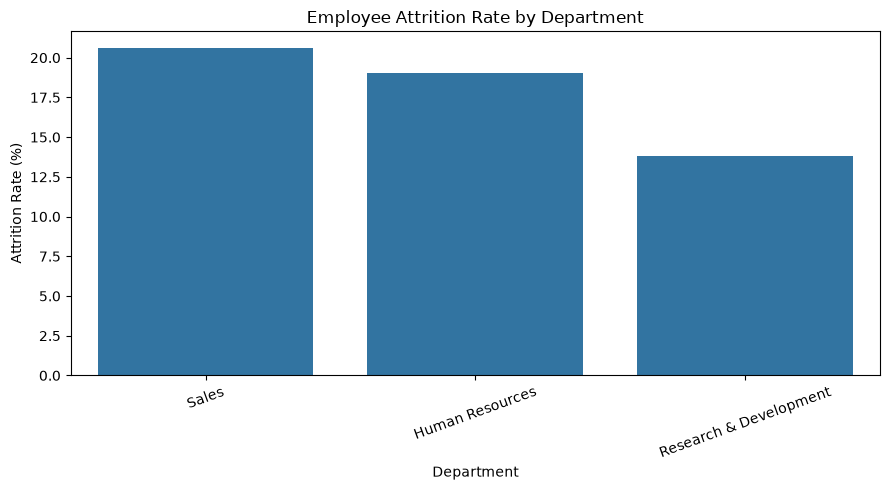

In [14]:
plot_data = department_rates.sort_values(
    "Attrition_Rate_Pct",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=plot_data.index,
    y=plot_data["Attrition_Rate_Pct"]
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()